# Randomized Benchmarking

In [5]:
from qiskit.quantum_info import random_clifford, Clifford
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    thermal_relaxation_error,
    amplitude_damping_error,
    ReadoutError,
)
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

{1: 0.9810872395833333, 2: 0.966015625, 4: 0.9510091145833334, 8: 0.9130859375, 16: 0.838671875, 32: 0.7399739583333333, 64: 0.6117513020833333, 128: 0.52587890625}
{'A': 0.49393234657741225, 'r': 0.9776534446548741, 'B': 0.49770465749864395, 'Error Per Clifford': 0.011173277672562931}


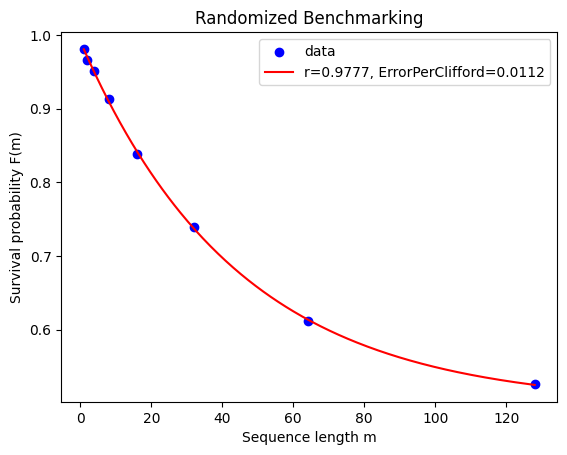

In [10]:
'''
Creating a method to select a noise model based oon inputs
'''

def make_noise_model(noise_type, params, n_qubits):
    nm = NoiseModel()
    if noise_type == "depolarizing":
        error1q = depolarizing_error(params["input_prob"], 1)
        nm.add_all_qubit_quantum_error(error1q, "u3")
        if n_qubits > 1:
            error2q = depolarizing_error(params["input_prob"], 2)
            nm.add_all_qubit_quantum_error(error2q, "cx")
        # this line says everytime a cicruit has a single qubit 
        # gate (u3) or a two qubit gate (cx) apply the depolarizing error
        # u3 is the gate that every other single qubit gate compiles to
        # Λ(ρ) = r·ρ + (1−r)·I/d   params: {"input_prob": r}

    elif noise_type == "amplitude_damping":
        error = amplitude_damping_error(params["input_prob"])
        nm.add_all_qubit_quantum_error(error, ["u3"])
        # Λ: |1⟩ → |0⟩ with prob gamma   params: {"input_prob": gamma}

    elif noise_type == "thermal_relaxation":
        '''
        Quick theory: Thermal relaxation — it models two physical decay processes on real hardware: 
        T1 — energy relaxation: excited qubit |1⟩ spontaneously decays to |0⟩ over time T1
        T2 — dephasing: qubit loses phase coherence (the X/Y components of the Bloch vector shrink) over time T2
        '''
        
        error1q = thermal_relaxation_error(params["T1"], params["T2"], params["tgate"])
        nm.add_all_qubit_quantum_error(error1q, ["u3"])
        if n_qubits > 1:
            error2q = thermal_relaxation_error(params["T1"], params["T2"], params["tgate"] * 2)
            nm.add_all_qubit_quantum_error(error2q, ["cx"])
        # Λ: T1 decay + T2 dephasing over gate time tgate, not this not the T gate. params: {"T1": ns, "T2": ns, "tgate": ns}  with T2 <= 2*T1

    return nm


def build_rb_circuit(n, m, interleaved=None):
    qc = QuantumCircuit(n, n)
    D = Clifford(qc) # initially this will be I
    #Clifford(qc) takes a quantum circuit and returns the Clifford object representing that circuit's unitary action. Since qc at this point is an empty circuit (no gates yet), Clifford(qc) is just the identity.
    for _ in range(m):
        C = random_clifford(n)
        qc.append(C, range(n)) # apply C to all qubits (range(n))
        D = D.compose(C) # adding now so that we can eventually
        # find the inv.

    inv = D.adjoint() # find the inverse of D
    qc.append(inv, range(n)) # apply the inverse to all qubits
    qc.measure(range(n), range(n)) # measure all qubits
    return qc


def run_experiment(noise_model, m_values, n_qubits, independent_sequences_per_m, shots):
    simulator = AerSimulator(noise_model=noise_model)
    results = {}
    for m in m_values:
        survival_probs = []
        for _ in range(independent_sequences_per_m):
            qc = build_rb_circuit(n_qubits, m, interleaved=None)
            qc = transpile(qc, basis_gates=["cx", "u3", "id", "reset", "measure"], optimization_level=0)
            counts = simulator.run(qc, shots=shots).result().get_counts()
            survival_prob = counts.get("0"*n_qubits, 0) /shots # look up all 0 strings in counts. Counts is dict like {"0": 950, "1": 74}. If "0" not found return 0 as default.
            survival_probs.append(survival_prob)
        results[m] = np.mean(survival_probs) # this is F(m, |0..0>)
    return results


def fit_rbdata(results):
    m_vals = np.array(sorted(results.keys()))
    f_vals = np.array([results[m] for m in m_vals])

    def rb_decay(m, A, r, B):
        return A * r**m + B
    
    p0 = [0.5, 0.99, 0.5]
    popt, _ = curve_fit(rb_decay, m_vals, f_vals, p0=p0, bounds=([0,0,0], [1,1,1]))
    A, r, B = popt

    d = 2**n_qubits
    error_per_clifford = (d-1)/d * (1-r)
    return {"A": A, "r": r, "B": B, "Error Per Clifford": error_per_clifford}

def plot_rb(results, fit, n_qubits):
    m_vals = np.array(sorted(results.keys()))
    f_vals = np.array([results[m] for m in m_vals])
    m_smooth = np.linspace(1, 128, 300)
    f_smooth = fit["A"] * fit["r"]**m_smooth + fit["B"]

    plt.scatter(m_vals, f_vals, color="blue", label="data")
    plt.plot(m_smooth, f_smooth, color="red", label=f"r={fit['r']:.4f}, ErrorPerClifford={fit['Error Per Clifford']:.4f}")
    plt.xlabel("Sequence length m")
    plt.ylabel("Survival probability F(m)")
    plt.title("Randomized Benchmarking")
    plt.legend()
    plt.show()

n_qubits = 1
m_values = [1, 2, 4, 8, 16, 32, 64, 128] # logarthimically spaced
independent_sequences_per_m = 30
shots = 1024

nm = make_noise_model("depolarizing", {"input_prob": 0.01}, n_qubits)
results = run_experiment(nm, m_values, n_qubits, independent_sequences_per_m, shots)
print(results)
fit = fit_rbdata(results)
print(fit)
plot_rb(results, fit, n_qubits)